# Question 4 : Front de Pareto coût total / émissions évitées

**Objectif.** Le décideur veut à la fois dépenser le moins possible et éviter le plus d'émissions possible. Ces deux
objectifs s'opposent. On cherche donc l'ensemble des meilleurs compromis (le front de Pareto), et le coût de la tonne de
CO$_2$ évitée.

**Méthode : l'$\varepsilon$-contrainte.** On garde le coût comme objectif et on borne les émissions. Le modèle contient
déjà cette borne : la trajectoire $E_{tot}(t) \le Q_{init} + a\,t$, réglée par la cible $Q_T = r \cdot Q_{init}$.
Chaque valeur de $r$ est un scénario de réduction et donne un point du front ($r = 1$ : aucune politique climatique).
On n'utilise pas la somme pondérée $\min C + \lambda E$ : le front d'un MILP n'est pas convexe, et elle n'en trouverait
qu'une partie.

**Indicateurs**, calculés à partir de chaque solution :
- CO$_2$ évité : $\Delta CO_2 = T \cdot Q_{init} - \sum_t E_{tot}(t)$, par rapport à une situation sans captage ;
- coût moyen par tonne évitée : $C_{tot} / \Delta CO_2$ ;
- coût marginal : $\Delta C_{tot} / \Delta(\Delta CO_2)$ entre deux scénarios voisins, le prix de la tonne *supplémentaire*.

## 1. Paramètres

- `INSTANCE` : `'small'`, `'medium'` ou `'large'`. Le notebook est enregistré sur Medium, l'instance de la Q3.
- `RUN_SOLVER` : `True` relance Gurobi pour tous les scénarios ; `False` recharge les résultats enregistrés
  (`pareto_<instance>.json`). Sur Medium, le calcul complet prend environ 1 h ; sur Small, environ 1 min.
- `RATIOS` : les scénarios $r = Q_T / Q_{init}$.
- `MIP_GAP` et `TIME_LIMIT` : gap d'arrêt de 0,1 % (plus strict qu'en Q3, pour ne pas créer de faux points dominés) et
  600 s maximum par scénario.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import logging
import numpy as np
import pandas as pd
import pyomo.environ as pyo
import matplotlib.pyplot as plt

import ccts_model
import solution_visualizer as sv

logging.getLogger('pyomo.core').setLevel(logging.ERROR)   # masque les avertissements des scénarios infaisables

INSTANCE = 'medium'
RUN_SOLVER = False
RATIOS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.075, 0.05]
TIME_LIMIT = 600    # secondes par scénario
MIP_GAP = 0.001

INSTANCE_FILES = {
    'small': 'CCTS_instance_small.txt',
    'medium': 'CCTS-instance_medium.txt',
    'large': 'CCTS-instance_large.txt',
}
data = ccts_model.read_instance(INSTANCE_FILES[INSTANCE])
Q_init = sum(data['E'].values())
print(f"Instance {INSTANCE} : N = {data['N']} noeuds, T = {data['T']} ans, Q_init = {Q_init:.1f} t/an")
print(f"Référence sans CCS : E_ref = T x Q_init = {data['T'] * Q_init:.1f} t")

Instance medium : N = 11 noeuds, T = 25 ans, Q_init = 1650.0 t/an
Référence sans CCS : E_ref = T x Q_init = 41250.0 t


## 2. Résolution des scénarios

Pour chaque $r$, on résout le modèle avec `ccts_model.resoudre_ccts`, puis on calcule les émissions **réellement
obtenues** et le CO$_2$ évité. Chaque solution passe l'audit de `solution_visualizer.py` (Hint 2) avec sa propre
trajectoire. Le scénario $r = 0.05$ est infaisable : même avec tous les sites équipés, il reste 10 % d'émissions.

In [2]:
TOL_AUDIT = 1e-5 * 0.9 * Q_init   # IntFeasTol de Gurobi x grand M du modèle
RESULTS_FILE = f'pareto_{INSTANCE}.json'

if RUN_SOLVER:
    rows = []
    trajectoires = {}
    captage = {}

    for r in RATIOS:
        print(f"--> Q_T_ratio = {r} ...", end=' ')
        res = ccts_model.resoudre_ccts(data, Q_T_ratio=r, mipgap=MIP_GAP, timelimit=TIME_LIMIT)

        if res['cost'] is None:
            print(f"{res['status']}")
            rows.append({'ratio': r, 'status': res['status'], 'time_sec': round(res['time_sec'], 1)})
            continue

        m = res['model']
        evite = res['E_ref'] - res['emissions_total']
        gap = max(0.0, (res['cost'] - res['lower_bound']) / res['cost']) if res['cost'] > 0 and res['lower_bound'] is not None else 0.0
        audit = sv.verify_constraints(data, m, tolerance=TOL_AUDIT, verbose=False, Q_T_ratio=r)
        rows.append({
            'ratio': r,
            'status': res['status'],
            'time_sec': round(res['time_sec'], 1),
            'gap_%': round(100 * gap, 3),
            'cost': res['cost'],
            'lower_bound': res['lower_bound'],
            'emissions_total': res['emissions_total'],
            'evite': evite,
            'reduction_%': 100 * evite / res['E_ref'],
            'cout_par_tonne': res['cost'] / evite if evite > 1e-6 else np.nan,
            'num_pipelines': res['num_pipelines'],
            'sites_captes': sum(1 for i in m.NC if m.CC[i, data['T'] - 1].value > 0.5),
            'audit_ok': audit['all_passed'],
            'ecart_audit': max(audit['checks'].values()),
        })
        trajectoires[r] = res['emissions_par_an']
        captage[r] = {i: next((t for t in m.T if m.CC[i, t].value > 0.5), None) for i in m.NC}
        print(f"{res['status']} en {res['time_sec']:.1f} s | coût = {res['cost']:.0f} | évité = {evite:.0f} t"
              f" | gap = {100 * gap:.2f} % | audit {'OK' if audit['all_passed'] else 'ÉCHEC'}")

    with open(RESULTS_FILE, 'w') as f:
        json.dump({'rows': rows, 'trajectoires': trajectoires, 'captage': captage}, f)
else:
    with open(RESULTS_FILE) as f:
        saved = json.load(f)
    rows = saved['rows']
    # JSON transforme les clés en texte : on revient aux ratios, années et numéros de site
    trajectoires = {float(r): {int(t): e for t, e in traj.items()} for r, traj in saved['trajectoires'].items()}
    captage = {float(r): {int(i): y for i, y in sites.items()} for r, sites in saved['captage'].items()}
    print(f"Résultats chargés depuis {RESULTS_FILE}")

df = pd.DataFrame(rows)
df.to_csv(f'pareto_{INSTANCE}.csv', index=False)
df

Résultats chargés depuis pareto_medium.json


,ratio,status,time_sec,gap_%,cost,lower_bound,emissions_total,evite,reduction_%,cout_par_tonne,num_pipelines,sites_captes,audit_ok,ecart_audit
0,1.000,optimal,0.2,0.000,0.000000e+00,0.000000e+00,41250.000000,0.000000,0.000000,NaN,0.0,0.0,True,0.00000
1,0.900,optimal,6.2,0.064,1.764152e+05,1.763021e+05,38571.649292,2678.350708,6.492971,65.867112,0.0,3.0,True,0.00000
2,0.800,optimal,12.9,0.079,2.509903e+05,2.507917e+05,35332.582722,5917.417278,14.345254,42.415521,0.0,4.0,True,0.00000
3,0.700,optimal,37.0,0.000,3.302827e+05,3.302827e+05,33208.403818,8041.596182,19.494779,41.071781,1.0,4.0,True,0.00000
4,0.600,optimal,52.7,0.000,4.422700e+05,4.422700e+05,31320.754125,9929.245875,24.070899,44.542150,3.0,7.0,True,0.00139
5,0.500,optimal,98.9,0.000,5.588267e+05,5.588267e+05,28292.822650,12957.177350,31.411339,43.128739,2.0,4.0,True,0.00000
6,0.400,optimal,183.6,0.000,6.614099e+05,6.614099e+05,26647.821010,14602.178990,35.399222,45.295287,3.0,7.0,True,0.00000
7,0.300,optimal,218.1,0.000,7.902329e+05,7.902329e+05,24835.195295,16414.804705,39.793466,48.141475,3.0,7.0,True,0.00000
8,0.200,optimal,231.4,0.000,8.985021e+05,8.985021e+05,22715.515179,18534.484821,44.932084,48.477320,5.0,8.0,True,0.00000
9,0.150,maxTimeLimit,809.3,7.493,9.563930e+05,8.847260e+05,21656.130010,19593.869990,47.500291,48.810829,5.0,9.0,True,0.00000


## 3. Front de Pareto

On retire les points **dominés** (un autre scénario est à la fois moins cher et moins émetteur), puis on repère les
points **non supportés** : ceux situés au-dessus de l'enveloppe convexe du front. Une somme pondérée ne les trouverait
jamais ; ce sont eux qui justifient l'$\varepsilon$-contrainte.

In [3]:
sol = df.dropna(subset=['cost']).sort_values('emissions_total').reset_index(drop=True)

def est_domine(k):
    a = sol.loc[k]
    autres = sol.drop(index=k)
    return ((autres['cost'] <= a['cost'] + 1e-6) & (autres['emissions_total'] <= a['emissions_total'] + 1e-6)
            & ((autres['cost'] < a['cost'] - 1e-6) | (autres['emissions_total'] < a['emissions_total'] - 1e-6))).any()

sol['domine'] = [est_domine(k) for k in sol.index]
front = sol[~sol['domine']].sort_values('evite').reset_index(drop=True)
front['cout_marginal'] = front['cost'].diff() / front['evite'].diff()

def supportes(front):
    # Points sur l'enveloppe convexe inférieure du front : les seuls accessibles par somme pondérée
    pts = front[['evite', 'cost']].to_numpy()
    hull = []
    for k, (x, y) in enumerate(pts):
        while len(hull) >= 2:
            (x1, y1), (x2, y2) = pts[hull[-2]], pts[hull[-1]]
            if (y2 - y1) / (x2 - x1) > (y - y2) / (x - x2) + 1e-9:   # la pente diminue : point au-dessus de la corde
                hull.pop()
            else:
                break
        hull.append(k)
    return [k in hull for k in range(len(pts))]

front['supporte'] = supportes(front)

print(f"{len(front)} points non dominés sur {len(sol)} scénarios faisables, dont {(~front['supporte']).sum()} non supportés.")
infaisables = df[df['cost'].isna()]['ratio'].tolist()
if infaisables:
    print(f"Scénarios infaisables : Q_T_ratio = {infaisables}")
front[['ratio', 'cost', 'emissions_total', 'evite', 'reduction_%', 'cout_par_tonne', 'cout_marginal',
       'sites_captes', 'num_pipelines', 'gap_%', 'supporte']]

11 points non dominés sur 12 scénarios faisables, dont 6 non supportés.
Scénarios infaisables : Q_T_ratio = [0.05]


,ratio,cost,emissions_total,evite,reduction_%,cout_par_tonne,cout_marginal,sites_captes,num_pipelines,gap_%,supporte
0,1.000,0.000000e+00,41250.000000,0.000000,0.000000,NaN,NaN,0.0,0.0,0.000,True
1,0.900,1.764152e+05,38571.649292,2678.350708,6.492971,65.867112,65.867112,3.0,0.0,0.064,False
2,0.800,2.509903e+05,35332.582722,5917.417278,14.345254,42.415521,23.023643,4.0,0.0,0.079,False
3,0.700,3.302827e+05,33208.403818,8041.596182,19.494779,41.071781,37.328465,4.0,1.0,0.000,True
4,0.600,4.422700e+05,31320.754125,9929.245875,24.070899,44.542150,59.326305,7.0,3.0,0.000,False
5,0.500,5.588267e+05,28292.822650,12957.177350,31.411339,43.128739,38.493857,4.0,2.0,0.000,True
6,0.400,6.614099e+05,26647.821010,14602.178990,35.399222,45.295287,62.360524,7.0,3.0,0.000,False
7,0.300,7.902329e+05,24835.195295,16414.804705,39.793466,48.141475,71.069844,7.0,3.0,0.000,False
8,0.200,8.985021e+05,22715.515179,18534.484821,44.932084,48.477320,51.078101,8.0,5.0,0.000,False
9,0.150,9.563930e+05,21656.130010,19593.869990,47.500291,48.810829,54.645751,9.0,5.0,7.493,True


Sur la figure de gauche, les points non supportés sont cerclés en rose, et les points dominés marqués d'une croix.
Quand Gurobi n'a pas prouvé l'optimum en 600 s, une barre grise va de la borne inférieure au coût trouvé.

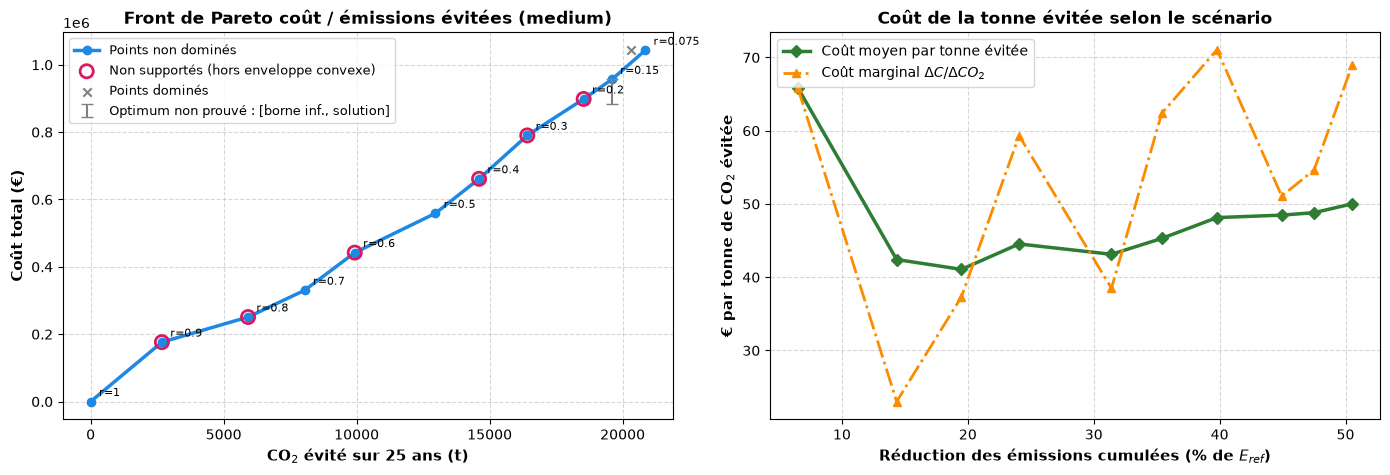

[OK] Figure enregistrée : figures/pareto_medium.png


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(front['evite'], front['cost'], marker='o', color='#1E88E5', linewidth=2.5, label='Points non dominés')
ns = front[~front['supporte']]
ax1.scatter(ns['evite'], ns['cost'], s=90, facecolors='none', edgecolors='#D81B60', linewidths=2, zorder=3,
            label='Non supportés (hors enveloppe convexe)')
nopt = front[front['gap_%'] > 100 * MIP_GAP]
if len(nopt):
    ax1.errorbar(nopt['evite'], nopt['cost'], yerr=[nopt['cost'] - nopt['lower_bound'], 0 * nopt['cost']],
                 fmt='none', ecolor='grey', capsize=4, label='Optimum non prouvé : [borne inf., solution]')
dom = sol[sol['domine']]
if len(dom):
    ax1.scatter(dom['evite'], dom['cost'], marker='x', color='grey', label='Points dominés')
for _, p in front.iterrows():
    ax1.annotate(f"r={p['ratio']:g}", (p['evite'], p['cost']), textcoords='offset points',
                 xytext=(6, 4), fontsize=8)
ax1.set_xlabel('CO$_2$ évité sur 25 ans (t)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Coût total (€)', fontsize=11, fontweight='bold')
ax1.set_title(f'Front de Pareto coût / émissions évitées ({INSTANCE})', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left', fontsize=9)

f = front[front['evite'] > 1e-6]
ax2.plot(f['reduction_%'], f['cout_par_tonne'], marker='D', color='#2E7D32', linewidth=2.5, label='Coût moyen par tonne évitée')
ax2.plot(f['reduction_%'], f['cout_marginal'], marker='^', color='#FB8C00', linestyle='-.', linewidth=2,
         label='Coût marginal $\\Delta C / \\Delta CO_2$')
ax2.set_xlabel('Réduction des émissions cumulées (% de $E_{ref}$)', fontsize=11, fontweight='bold')
ax2.set_ylabel('€ par tonne de CO$_2$ évitée', fontsize=11, fontweight='bold')
ax2.set_title('Coût de la tonne évitée selon le scénario', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.savefig(f'figures/pareto_{INSTANCE}.png', dpi=300)
plt.show()
print(f"[OK] Figure enregistrée : figures/pareto_{INSTANCE}.png")

**Ce qu'on observe (Medium)**
- **Éviter plus coûte toujours plus.** Le coût passe de 0 à 1,04 M€, pour au plus 50,5 % des émissions évitées.
- **Le coût moyen par tonne dessine un U** : 66 €/t à $r = 0.9$, 41 €/t à $r = 0.7$, puis 50 €/t. Au début, le CO$_2$ part
  en camion ou en train, ce qui coûte cher. À partir de $r = 0.7$, les volumes justifient un premier pipeline : ce sont
  des économies d'échelle. (Sur Small, tout passe par pipeline et le coût moyen augmente doucement, de 1,29 à 1,61 €/t.)
- **Le front n'est pas convexe** : 6 points sur 11 sont non supportés, et le coût marginal varie sans régularité
  (23 à 71 €/t). Une taxe carbone revient à une somme pondérée : elle ne mènerait jamais à ces scénarios.
- **$r = 0.1$ est écarté** : sa solution (gap de 28,5 %) coûte plus cher que celle de $r = 0.075$, qui évite pourtant plus
  de CO$_2$. Elle n'est donc pas optimale.

## 4. Ce qui change d'un scénario à l'autre

**Les émissions année par année.** Le captage est installé le plus tard possible, quand la trajectoire l'impose : les
émissions suivent un escalier juste sous le plafond. C'est pourquoi on n'évite qu'environ la moitié des émissions,
et non 90 % comme si tous les sites étaient équipés dès le départ.

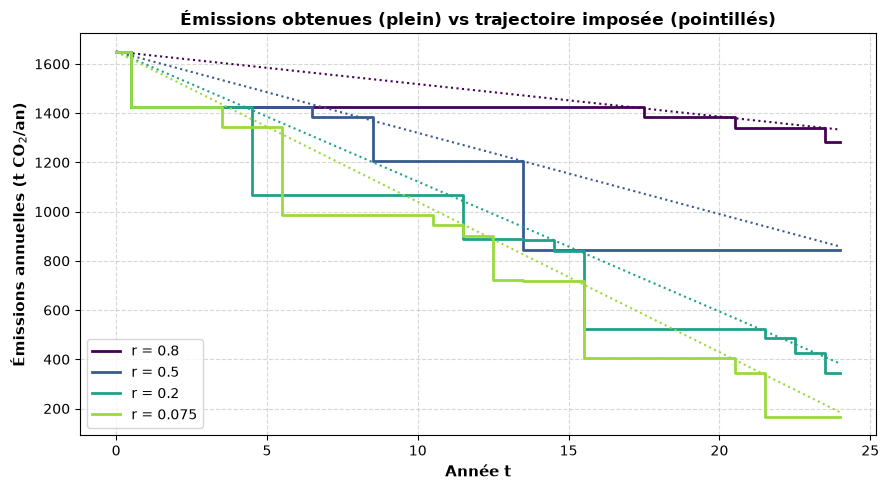

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
choix = [r for r in [0.8, 0.5, 0.2, 0.075] if r in trajectoires]   # 0.075 plutôt que 0.1, non prouvé optimal sur Medium
couleurs = plt.cm.viridis(np.linspace(0, 0.85, len(choix)))
for r, c in zip(choix, couleurs):
    ans = sorted(trajectoires[r])
    pente = (r * Q_init - Q_init) / data['T']
    ax.step(ans, [trajectoires[r][t] for t in ans], where='mid', color=c, linewidth=2, label=f'r = {r:g}')
    ax.plot(ans, [Q_init + pente * t for t in ans], color=c, linestyle=':', linewidth=1.5)
ax.set_xlabel('Année t', fontsize=11, fontweight='bold')
ax.set_ylabel('Émissions annuelles (t CO$_2$/an)', fontsize=11, fontweight='bold')
ax.set_title('Émissions obtenues (plein) vs trajectoire imposée (pointillés)', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.savefig(f'figures/pareto_trajectoires_{INSTANCE}.png', dpi=300)
plt.show()

**Les sites équipés.** Chaque case donne l'année où le captage est installé sur un site, pour un scénario.

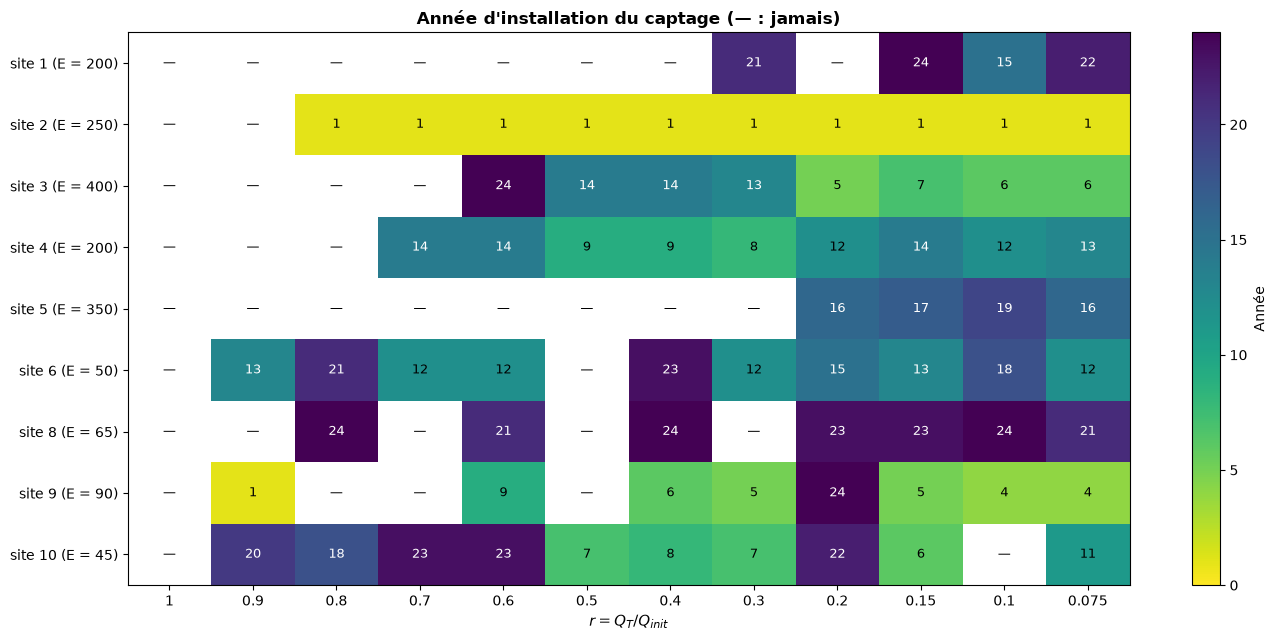

In [6]:
sites = sorted(data['capture'])
ratios = sorted(captage, reverse=True)
grille = np.array([[np.nan if captage[r][i] is None else captage[r][i] for r in ratios] for i in sites], dtype=float)

fig, ax = plt.subplots(figsize=(1.0 * len(ratios) + 2, 0.5 * len(sites) + 2))
im = ax.imshow(grille, cmap='viridis_r', aspect='auto', vmin=0, vmax=data['T'] - 1)
for n in range(len(sites)):
    for k in range(len(ratios)):
        txt = '—' if np.isnan(grille[n, k]) else f"{int(grille[n, k])}"
        ax.text(k, n, txt, ha='center', va='center', fontsize=9,
                color='white' if grille[n, k] > data['T'] / 2 else 'black')
ax.set_xticks(range(len(ratios)), [f"{r:g}" for r in ratios])
ax.set_yticks(range(len(sites)), [f"site {i} (E = {data['E'][i]:g})" for i in sites])
ax.set_xlabel('$r = Q_T / Q_{init}$', fontsize=11, fontweight='bold')
ax.set_title("Année d'installation du captage (— : jamais)", fontsize=12, fontweight='bold')
fig.colorbar(im, ax=ax, label='Année')
plt.tight_layout()
plt.savefig(f'figures/pareto_captage_{INSTANCE}.png', dpi=300)
plt.show()

Il n'y a **pas d'ordre fixe** pour équiper les sites : 7 sites sont équipés à $r = 0.6$, mais seulement 4 à $r = 0.5$.
Durcir l'objectif peut réorganiser tout le réseau, donc chaque scénario doit être réoptimisé.

## 5. Difficulté de résolution

Temps de calcul et gap final de Gurobi pour chaque scénario.

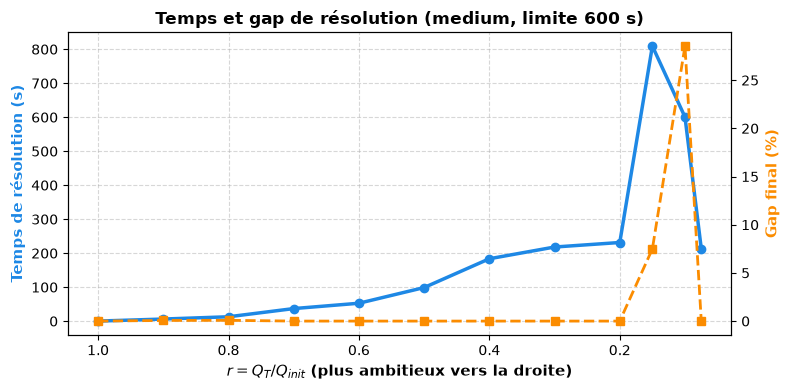

In [7]:
perf = df.dropna(subset=['cost']).sort_values('ratio', ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(perf['ratio'], perf['time_sec'], marker='o', color='#1E88E5', linewidth=2.5)
ax.invert_xaxis()
ax.set_xlabel('$r = Q_T / Q_{init}$ (plus ambitieux vers la droite)', fontsize=11, fontweight='bold')
ax.set_ylabel('Temps de résolution (s)', color='#1E88E5', fontsize=11, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax_gap = ax.twinx()
ax_gap.plot(perf['ratio'], perf['gap_%'], marker='s', color='#FB8C00', linestyle='--', linewidth=2)
ax_gap.set_ylabel('Gap final (%)', color='#FB8C00', fontsize=11, fontweight='bold')
ax.set_title(f'Temps et gap de résolution ({INSTANCE}, limite {TIME_LIMIT} s)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'figures/pareto_performance_{INSTANCE}.png', dpi=300)
plt.show()

Plus l'objectif est ambitieux, plus le problème est difficile : 0,2 s à $r = 1$, 231 s à $r = 0.2$, et l'optimum n'est
plus prouvé en 600 s à $r = 0.15$ et $0.1$. Le problème redevient plus simple à $r = 0.075$ (213 s), car presque tous les
sites doivent y être équipés. La difficulté se concentre là où beaucoup de réseaux différents ont des coûts proches.

## 6. Trajectoire linéaire ou budget carbone

Faire varier $Q_T$ impose une baisse régulière **chaque année**. Une alternative est de fixer seulement un budget sur
les émissions **totales** des 25 ans. On recalcule chaque point avec ce budget, pour les mêmes émissions totales, et on
compare les coûts.

In [8]:
def resoudre_budget(eps):
    # Même modèle, mais la trajectoire annuelle est remplacée par un budget d'émissions cumulées
    m = ccts_model.build_ccts_model(data, Q_T_ratio=1.0)
    m.emissions.deactivate()
    m.budget = pyo.Constraint(expr=sum(m.emissions[t].body for t in m.T) <= eps)
    opt = pyo.SolverFactory('gurobi')
    opt.options['MIPGap'] = MIP_GAP
    opt.options['TimeLimit'] = TIME_LIMIT
    results = opt.solve(m)
    return pyo.value(m.objective), str(results.solver.termination_condition)

BUDGET_FILE = f'pareto_budget_{INSTANCE}.json'
if RUN_SOLVER:
    budget = []
    for _, p in front[front['evite'] > 1e-6].iterrows():
        cost_b, status_b = resoudre_budget(p['emissions_total'])
        budget.append({'ratio': p['ratio'], 'evite': p['evite'], 'cost_trajectoire': p['cost'],
                       'cost_budget': cost_b, 'status_budget': status_b})
        print(f"r = {p['ratio']:g} : coût trajectoire = {p['cost']:.0f} | coût budget = {cost_b:.0f} ({status_b})")
    with open(BUDGET_FILE, 'w') as f:
        json.dump(budget, f)
else:
    with open(BUDGET_FILE) as f:
        budget = json.load(f)

df_budget = pd.DataFrame(budget)
df_budget['surcout_%'] = 100 * (df_budget['cost_trajectoire'] / df_budget['cost_budget'] - 1)
df_budget.round(2)

,ratio,evite,cost_trajectoire,cost_budget,status_budget,surcout_%
0,0.90,2678.35,176415.23,91548.15,optimal,92.70
1,0.80,5917.42,250990.34,207414.61,optimal,21.01
2,0.70,8041.60,330282.68,293561.35,optimal,12.51
3,0.60,9929.25,442269.96,370633.71,optimal,19.33
4,0.50,12957.18,558826.72,503661.25,optimal,10.95
5,0.40,14602.18,661409.88,582778.07,optimal,13.49
6,0.30,16414.80,790232.91,701153.46,maxTimeLimit,12.70
7,0.20,18534.48,898502.15,820289.80,optimal,9.53
8,0.15,19593.87,956393.04,894450.60,optimal,6.93
9,0.08,20846.67,1042794.13,983312.04,optimal,6.05


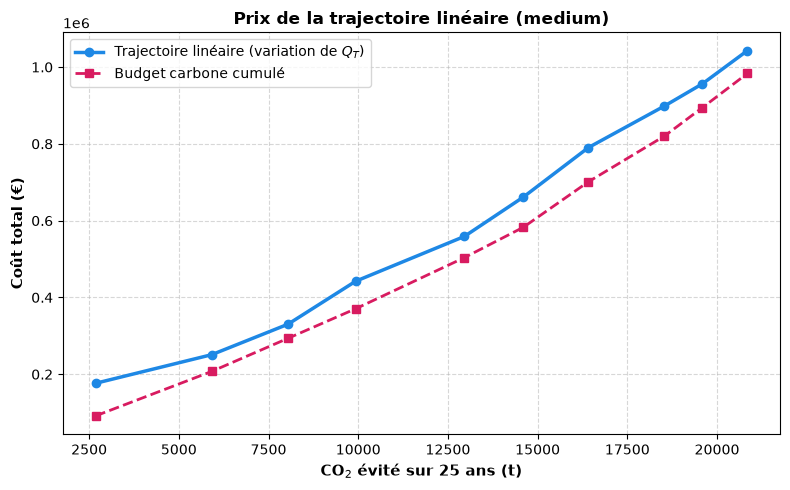

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_budget['evite'], df_budget['cost_trajectoire'], marker='o', color='#1E88E5', linewidth=2.5,
        label='Trajectoire linéaire (variation de $Q_T$)')
ax.plot(df_budget['evite'], df_budget['cost_budget'], marker='s', color='#D81B60', linestyle='--', linewidth=2,
        label='Budget carbone cumulé')
ax.set_xlabel('CO$_2$ évité sur 25 ans (t)', fontsize=11, fontweight='bold')
ax.set_ylabel('Coût total (€)', fontsize=11, fontweight='bold')
ax.set_title(f"Prix de la trajectoire linéaire ({INSTANCE})", fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.savefig(f'figures/pareto_budget_{INSTANCE}.png', dpi=300)
plt.show()

La trajectoire linéaire coûte 12,6 % de plus en médiane (de 6 % à 93 %, le maximum à $r = 0.9$) ; sur Small, 4,2 % de
plus en moyenne. Elle oblige à réduire un peu chaque année dès le début, avec des moyens chers, alors qu'un budget permet
de concentrer l'effort. Le budget est plus économique, mais il autorise à reporter l'effort : la trajectoire est un
garde-fou dont on mesure ici le prix.

## 7. Conclusion

**Réponse à la question.** On calcule le front de Pareto par $\varepsilon$-contrainte, en faisant varier $Q_T$. La somme
pondérée ne suffit pas : elle manque 5 points sur 12 sur Small et 6 sur 11 sur Medium.

**À retenir (Medium)**
- Éviter 20 % des émissions coûte environ 330 k€, en éviter 45 % environ 900 k€ ; on ne dépasse pas 50 %.
- La tonne évitée coûte de 41 à 66 €/t ; le premier pipeline apporte des économies d'échelle.
- Les scénarios non supportés ne s'obtiennent que par une cible réglementaire comme $Q_T$, pas par une taxe carbone.
- Il n'y a pas d'ordre fixe pour équiper les sites, et la difficulté de résolution croît avec l'ambition.

**Limites**
- Le coût du captage n'est pas dans l'objectif : les coûts par tonne ne comptent que le transport.
- Sur Medium, $r = 0.15$ et $0.1$ ne sont pas résolus à l'optimum en 600 s.
- Le front n'est pas calculé sur Large : une seule résolution y laisse 21,5 % de gap après une heure (Q2).
- Les valeurs en €/t dépendent de l'instance ; seules les tendances sont générales.